In [1]:
import sys 
import os
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/gaussfiltax')
import argparse
import jax.numpy as jnp
import jax.random as jr
from jax import vmap
import time
from flax import nnx
import matplotlib.pyplot as plt
import tensorflow_probability.substrates.jax.distributions as tfd # type: ignore
from util.misc import get_exp_dir, get_exp_data, get_data_for

exp_root = '/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/exps'

## View experiment

In [2]:
ncomps = 100
M, N, L = 2, 2, 2
num_prt = 100
ac1 = 'prop'
r1 = 0.9
ac2 = 'prop'
r2 = 0.9

sim_args = {'ssm' : 'mtt',
            'state_dim' : 4,
            'emission_dim' : 2,
            'num_timesteps' : 500
        }

args_lgsf = {'n_comps' : ncomps,
            'n_iters' : 1
        }

args_ugsf = {'n_comps' : ncomps,
            'n_iters' : 1,
            'alpha' : 0.001,
            'beta' : 2.0,
            'kappa' : 0.0
        }


args_lagsf = {'M' : M,
            'N' : N,
            'L' : L,
            'ac1' : ac1,
            'r1' : r1,
            'ac2' : ac2,
            'r2' : r2,
            'n_iters' : 1
        }

args_uagsf = {'M' : M,
            'N' : N,
            'L' : L,
            'ac1' : ac1,
            'r1' : r1,
            'ac2' : ac2,
            'r2' : r2,
            'n_iters' : 1
        }

args_bpf = {'M' : num_prt,
            'ess' : 0.5
        }

args_apf = {'M' : num_prt,
            'ess' : 0.5
        }

inf_args = {'lgsf' : args_lgsf,
            'ugsf' : args_ugsf,
            'lagsf' : args_lagsf,
            'uagsf' : args_uagsf,
            'bpf' : args_bpf,
            'apf' : args_apf
        }

out = {}
for alg in inf_args.keys():

        try:

            data = get_data_for(alg, sim_args, inf_args[alg], 5)
            out[alg] = data

        except Exception as e:
              
                print(f"Error processing algorithm {alg}: {e}")
                out[alg] = None
    

Error processing algorithm ugsf: Ran out of input


lgsf - Trial 1 - LPE: nan, BS: 394.4070, ME: 0.0406, MSE: 11365571.0000
Error retrieving error metrics for ugsf: 'NoneType' object is not subscriptable
Error plotting algorithm ugsf: 'NoneType' object is not subscriptable
lagsf - Trial 1 - LPE: 1041.0710, BS: 0.3331, ME: 0.3292, MSE: 0.1992
uagsf - Trial 1 - LPE: 10.8298, BS: 0.0127, ME: 0.0121, MSE: 0.0021
bpf - Trial 1 - LPE: 6.0246, BS: 10.4450, ME: 1.3149, MSE: 122.6625
apf - Trial 1 - LPE: 1970066.2500, BS: 15.8830, ME: 13.7987, MSE: 320.8580


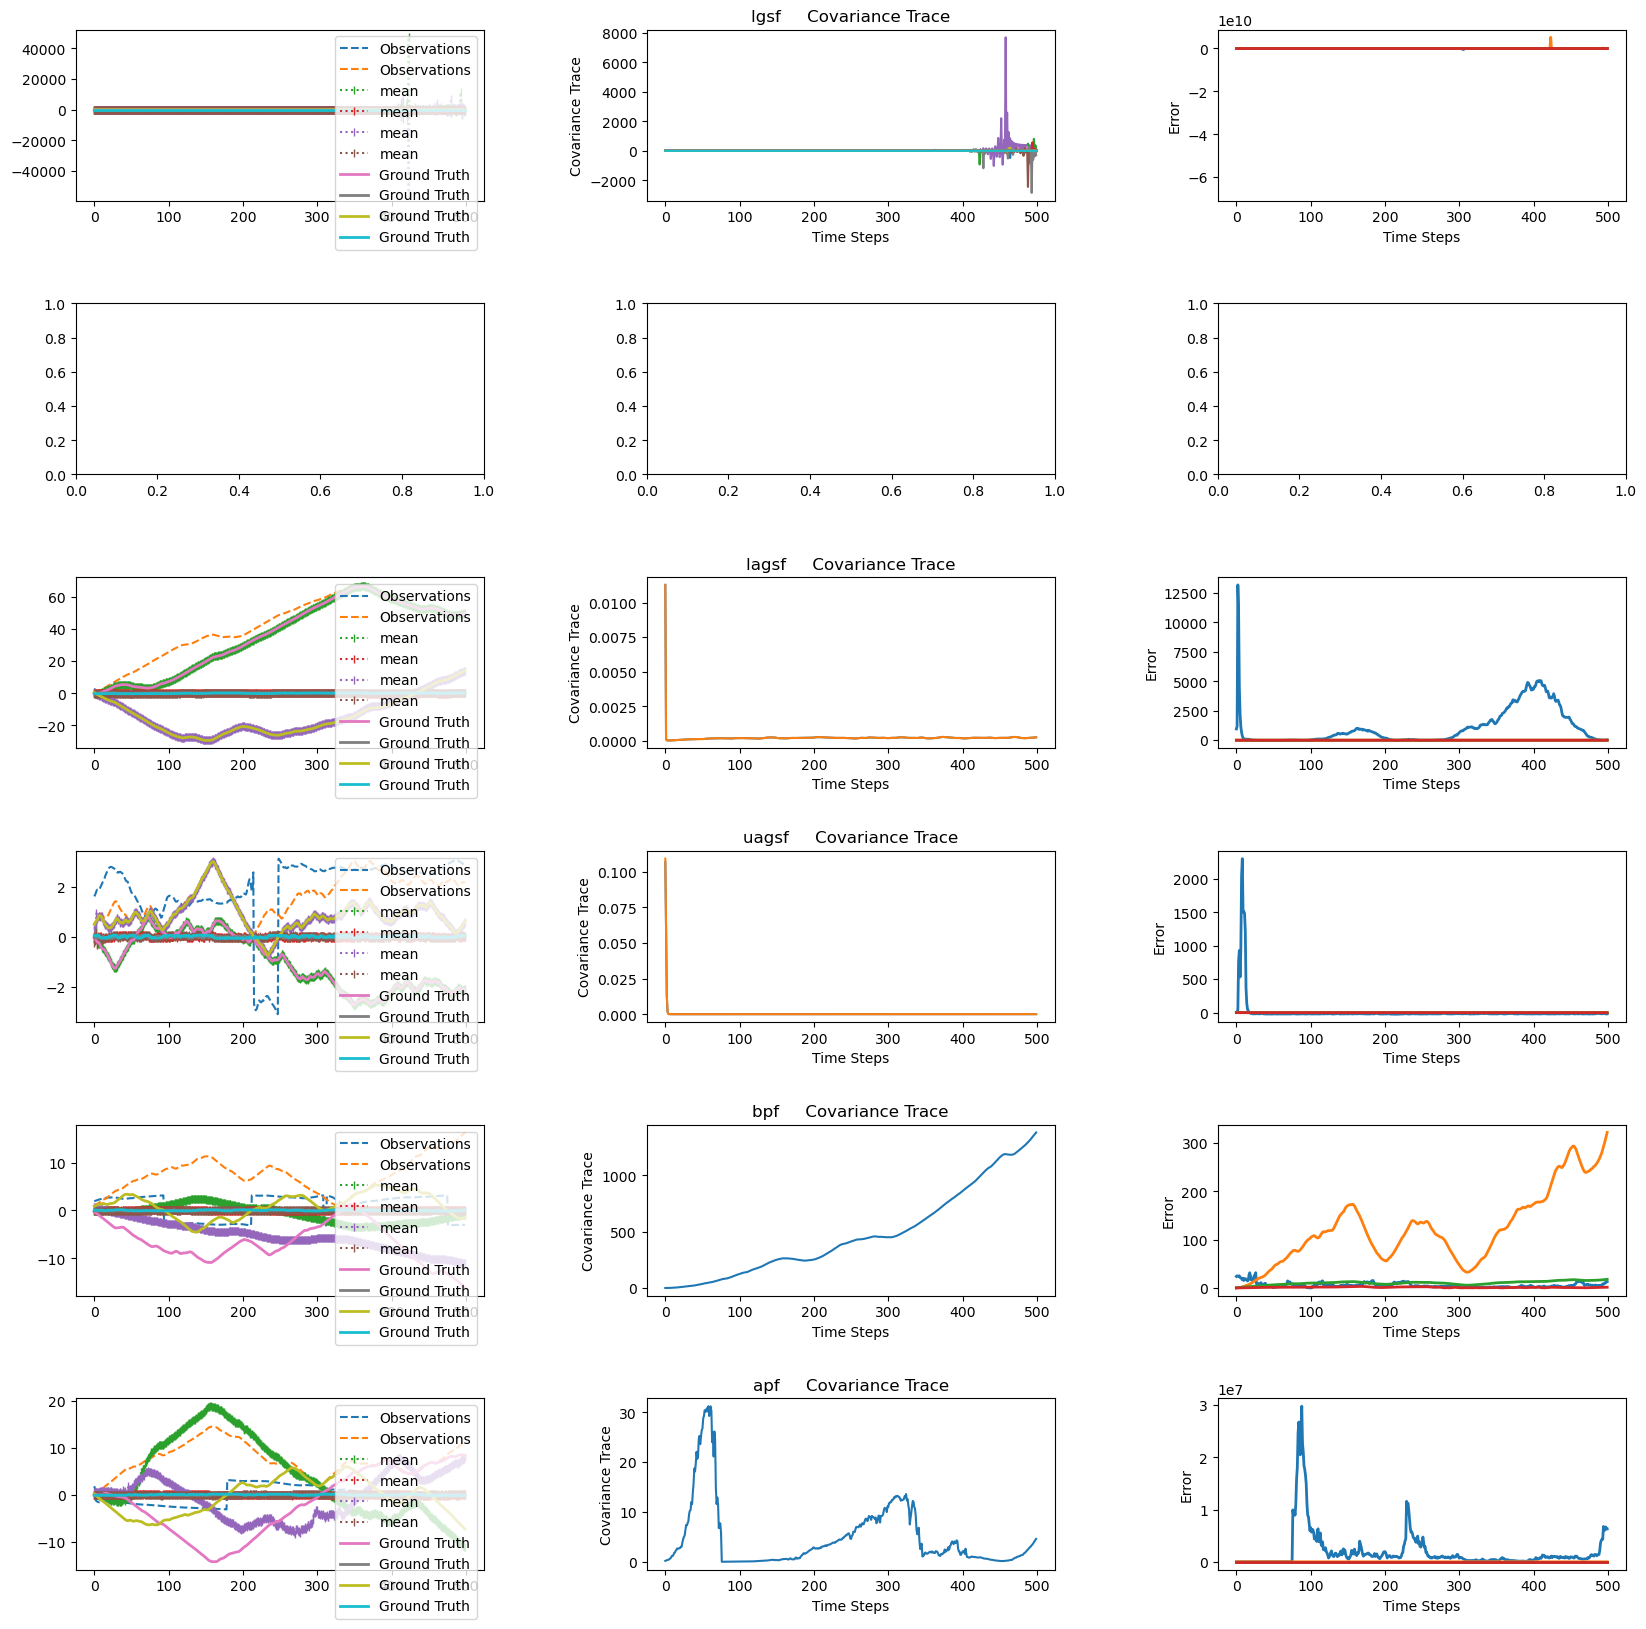

In [3]:
trial = 1

fig, ax = plt.subplots(6, 3, figsize=(20, 20))
plt.subplots_adjust(wspace=0.4, hspace=0.6)
trace = lambda cov: jnp.trace(cov) if cov.ndim == 2 else cov

for i, alg in enumerate(out.keys()):

    try:

        try:

            (lpe, lpe_t), (bs, bs_t), (me, me_t), (mse, mse_t) = out[alg]['lpe'][trial], out[alg]['bs'][trial], out[alg]['me'][trial], out[alg]['mse'][trial]
            print(f"{alg} - Trial {trial} - LPE: {lpe:.4f}, BS: {bs:.4f}, ME: {me:.4f}, MSE: {mse:.4f}")

        except Exception as e:

            print(f"Error retrieving error metrics for {alg}: {e}")

        if alg == 'bpf' or alg == 'apf':

            means = out[alg]['results'][trial][0]['particles']
            covs = vmap(lambda t: trace(jnp.cov(means[:, t, :].T)))(jnp.arange(means.shape[1]))
            means = means.mean(axis=0)

        else:

            means = out[alg]['results'][trial]['means'].mean(axis=0)
            covs = jnp.trace(out[alg]['results'][trial]['covariances'], axis1=2, axis2=3).T
        
        states = out[alg]['gt'][trial][0]
        observations = out[alg]['gt'][trial][1]

        ax[i, 0].plot(observations, label='Observations', linestyle='dashed')
        ax[i, 0].plot(means, label='mean', marker='|', linestyle='dotted')
        ax[i, 0].plot(states, label='Ground Truth', linewidth=2)
        ax[i, 0].legend(fontsize=10)

        ax[i, 1].plot(covs, label='Covariance Trace')
        ax[i, 1].set_title(alg + '     Covariance Trace')
        ax[i, 1].set_xlabel('Time Steps')
        ax[i, 1].set_ylabel('Covariance Trace')

        ax[i, 2].plot(lpe_t, label='LPE', linewidth=2)
        ax[i, 2].plot(mse_t, label='MSE', linewidth=2)
        ax[i, 2].plot(bs_t, label='BS', linewidth=2)
        ax[i, 2].plot(me_t, label='ME', linewidth=2)
        ax[i, 2].set_xlabel('Time Steps')
        ax[i, 2].set_ylabel('Error')
        # ax[i, 2].legend(fontsize=10)
    
    except Exception as e:

        print(f"Error plotting algorithm {alg}: {e}")


plt.show()

AttributeError: 'NoneType' object has no attribute 'get'

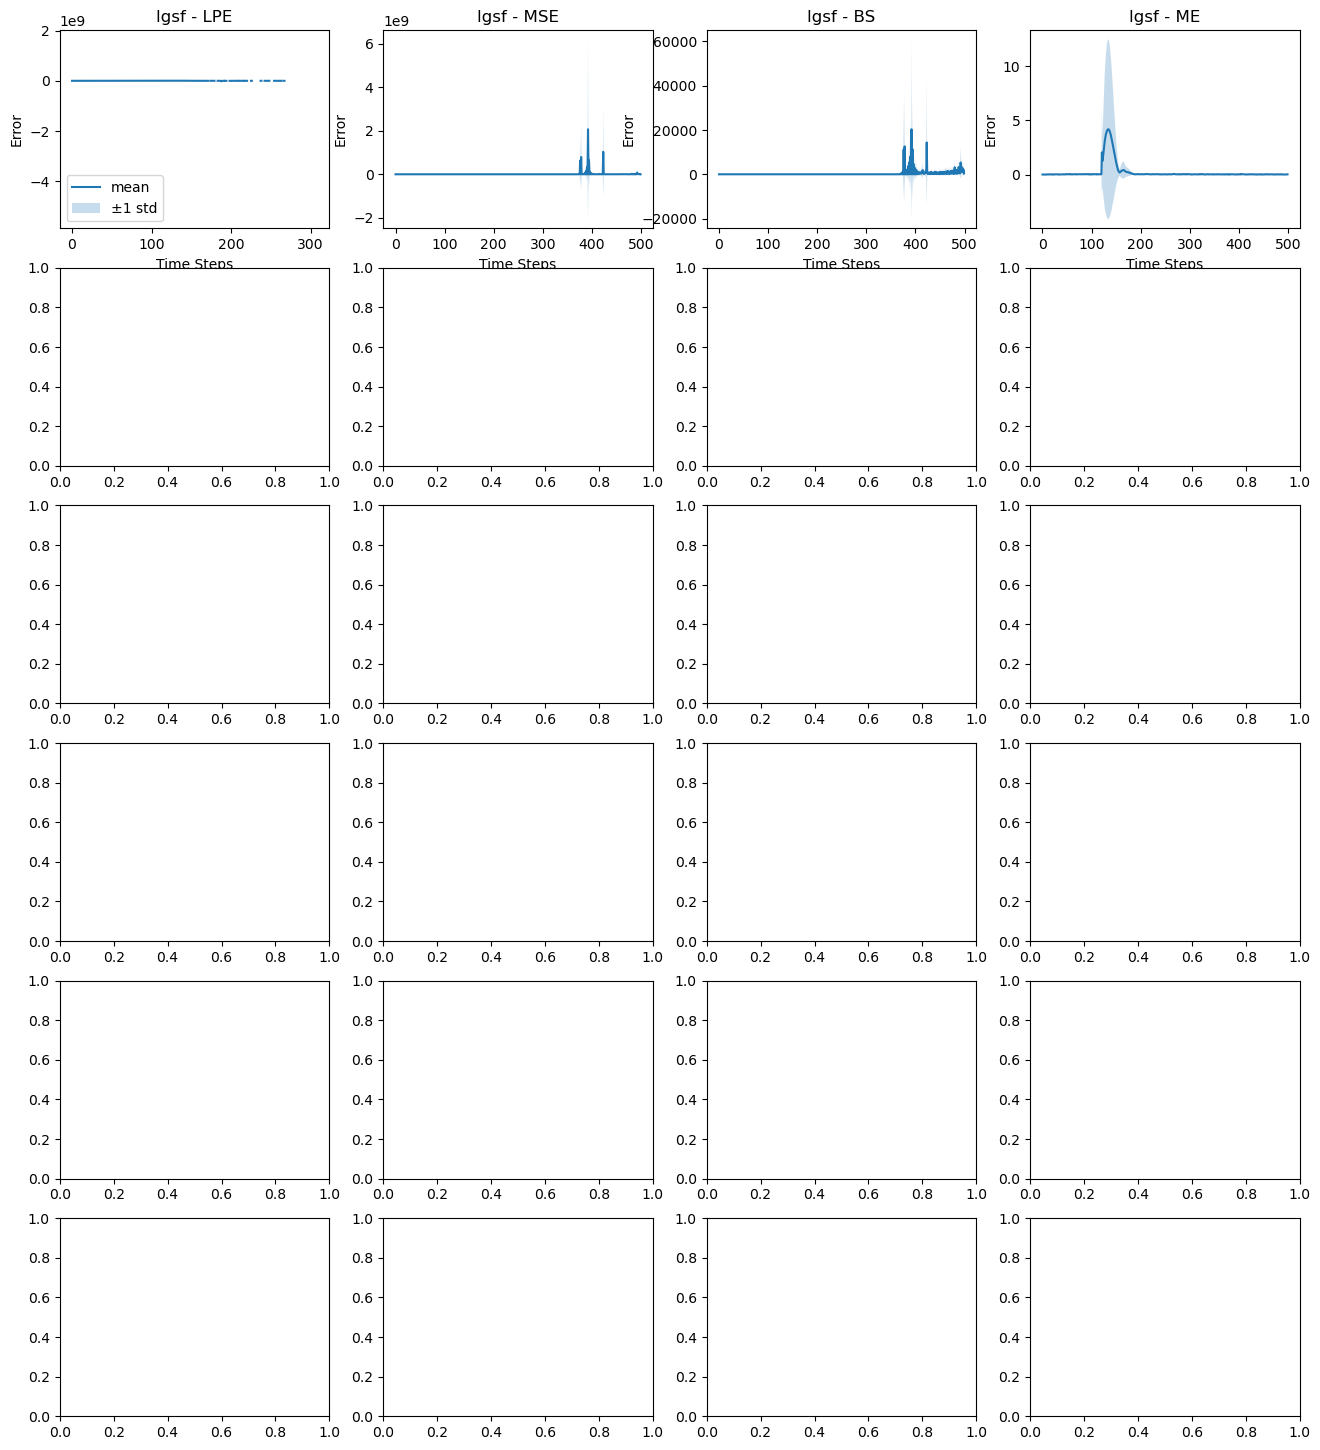

In [4]:
import numpy as np
algs = list(out.keys())
metrics = ['lpe', 'mse', 'bs', 'me']

fig, axes = plt.subplots(len(algs), len(metrics), figsize=(16, 3 * len(algs)), squeeze=False)
for i, alg in enumerate(algs):
    for j, met in enumerate(metrics):
        trials = out[alg].get(met, [])
        valid_series = []
        for entry in trials:
            try:
                _, ts = entry
                ts = np.asarray(ts)
                valid_series.append(ts)
            except Exception:
                continue

        ax = axes[i, j]
        ax.set_title(f"{alg} - {met.upper()}")
        ax.set_xlabel("Time Steps")
        ax.set_ylabel("Error")

        if len(valid_series) == 0:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            continue

        arr = np.vstack(valid_series)  # shape: (n_trials, T)
        mean = arr.mean(axis=0)
        std = arr.std(axis=0)
        x = np.arange(mean.size)

        ax.plot(x, mean, lw=1.5, label='mean')
        ax.fill_between(x, mean - std, mean + std, alpha=0.25, label='±1 std')
        if i == 0 and j == 0:
            ax.legend()

plt.tight_layout()
plt.show()

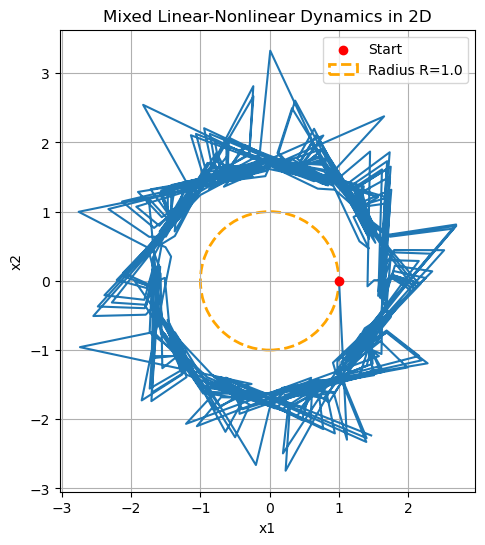

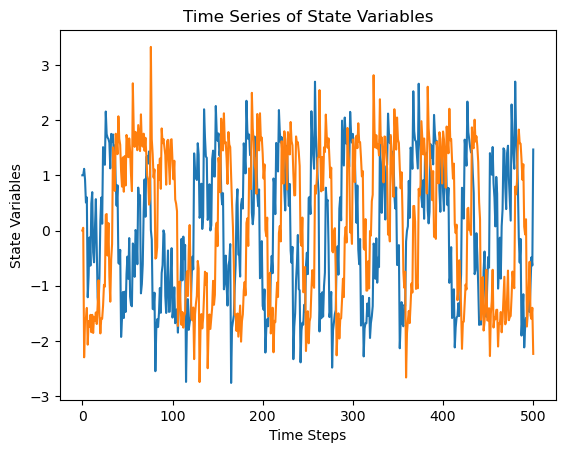

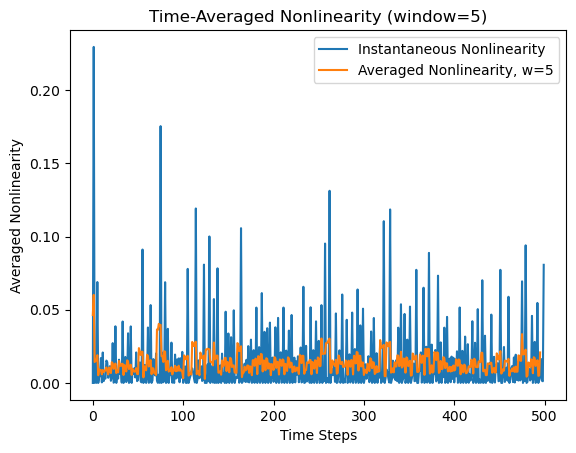

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Step function from before
def step_dynamics(x, dt=0.05, omega=1.0, epsilon=100.0, R=1.0, delta=0.5, k=10):
    """
    Mixed linear-nonlinear step with globally complex, locally linearizable nonlinearity.

    Parameters:
        x      : np.array of shape (2,), current state
        dt     : float, time step size
        omega  : float, angular frequency
        epsilon: float, strength of nonlinear perturbation
        R      : float, radius where nonlinearity is centered
        delta  : float, controls spread of nonlinearity
        k      : int, angular frequency of nonlinearity variation

    Returns:
        np.array of shape (2,), next state
    """
    x1, x2 = x
    r = np.sqrt(x1**2 + x2**2)
    theta = np.arctan2(x2, x1)

    # Smooth envelope around radius R
    envelope = np.exp(-((r - R)**2) / delta**2)

    # High-frequency angular variation
    bump = np.sin(k * theta)

    # Nonlinear perturbation term
    phi = envelope * bump

    # Main system dynamics
    dx1 = (1 - r**2) * x1 - omega * x2 + epsilon * phi * x2
    dx2 = (1 - r**2) * x2 + omega * x1 - epsilon * phi * x1

    return np.array([x1 + dt * dx1, x2 + dt * dx2]), phi**2

# Simulation parameters
T = 500             # number of time steps
x0 = np.array([1.0, 0.0])  # initial condition
trajectory = [x0]
nonlinearity = []

# Simulate
x = x0
R0 = 1.0

for _ in range(T):

    x, phi2 = step_dynamics(x, R = R0)
    trajectory.append(x)
    nonlinearity.append(phi2)

trajectory = np.array(trajectory)
nonlinearity = np.array(nonlinearity)

# Plot trajectory
plt.figure(figsize=(6, 6))
plt.plot(trajectory[:, 0], trajectory[:, 1], lw=1.5)
plt.scatter(x0[0], x0[1], color='red', label='Start', zorder=5)

circle = plt.Circle((0, 0), R0, color='orange', fill=False, linestyle='--', linewidth=2, label=f'Radius R={R0}')
plt.gca().add_patch(circle)
plt.gca().set_aspect('equal')

plt.title("Mixed Linear-Nonlinear Dynamics in 2D")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)
plt.legend()
plt.show()

plt.plot(trajectory)
plt.title("Time Series of State Variables")
plt.xlabel("Time Steps")
plt.ylabel("State Variables")   
plt.show()

plt.plot(nonlinearity, label='Instantaneous Nonlinearity')
window = 5  # size of the window
avg_nonlinearity = np.convolve(nonlinearity, np.ones(window)/window, mode='valid')
plt.plot(avg_nonlinearity, label='Averaged Nonlinearity, w={}'.format(window))
plt.title(f"Time-Averaged Nonlinearity (window={window})")
plt.xlabel("Time Steps")
plt.ylabel("Averaged Nonlinearity")
plt.legend()
plt.show()